In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.preprocessing import combine_the_data, dict_the_data 

In [46]:
# def read_the_data(scan: str, path: str): 
#     data = pd.read_csv(f"../../../DeltabotController/python/{path}/scan_{scan}/data.csv")
#     return (data)

# def relative_cx_cy(data, start_cx, start_cy): 
#     data["cx_rel"] = data["cx"] - start_cx
#     data["cy_rel"] = data["cy"] - start_cy

# def px_to_mm(data, x_conversion, y_conversion): 
#     data["cx_mm"] = data["cx_rel"]*x_conversion
#     data["cy_mm"] = data["cy_rel"]*y_conversion

# def process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy):
#     data = read_the_data(scan, path)
#     relative_cx_cy(data, start_cx, start_cy)   
#     px_to_mm(data, x_conversion, y_conversion)
#     return data

# def combine_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
#     """creates one dataframe of all the scans"""
#     df_list = []
#     for scan in scans:
#         data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
#         # if scan[1]:
#         #     data["cx_mm"] = -data["cx_mm"]
#         df_list.append(data)
#     combined_data = pd.concat(df_list,ignore_index=True)
#     return combined_data

# def list_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
#     all_data = []
#     for scan in scans:
#         data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
#         all_data.append(data)
#         print(all_data)
#     return all_data

# def dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy):
#     """creates a dictionary of scan_name: data (df)"""
#     all_data = {}
#     for scan in scans:
#         data = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
#         all_data[f"{scan}"] = data
#     return all_data

<h3>Importing The Data

In [47]:
#Specific to these scans
path = "scans/data"
scans = []
for x in [19,21,40,42,43]: scans.append(f"00{x}_0_0")
for x in [20,41]: scans.append(f"00{x}_mesh") #41 is wrong circle until point 19
for x in [22,24,26,28,30,32,34,36,38]: scans.append(f"00{x}_centre") #34 is wrong circle
for x in [23,25,27,29,31,33,35,37,39]: scans.append(f"00{x}_dmesh") #Scan 29 is wrong circle 
# for x in range(19,39): scans.append(f"000{x}_*")
print(scans)
scans.sort() #need to sort the scans into the order they were taken!!
print(scans)
x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 294 #px
start_cy = 260 #px

['0019_0_0', '0021_0_0', '0040_0_0', '0042_0_0', '0043_0_0', '0020_mesh', '0041_mesh', '0022_centre', '0024_centre', '0026_centre', '0028_centre', '0030_centre', '0032_centre', '0034_centre', '0036_centre', '0038_centre', '0023_dmesh', '0025_dmesh', '0027_dmesh', '0029_dmesh', '0031_dmesh', '0033_dmesh', '0035_dmesh', '0037_dmesh', '0039_dmesh']
['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']


In [48]:
print(scans)
data_concat = combine_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)
print(data_concat.last_valid_index())
print(len(data_concat.dropna()))
display(data_concat.tail(10))

['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']
3694
3562


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,...,track_cy,track_radius,roi_x_min,roi_y_min,roi_x_max,roi_y_max,cx_rel,cy_rel,cx_mm,cy_mm
3685,435,924.1277,-0.5,-1.0,-0.499994,-1.0,-5120,4777,343,0.0,...,362.0,6.0,220.0,222.0,500.0,502.0,66.0,102.0,-0.600000,-0.927273
3686,436,926.2037,-0.6,-1.0,-0.599903,-1.0,-5120,5220,-100,0.0,...,364.0,6.0,238.0,224.0,518.0,504.0,84.0,104.0,-0.763636,-0.945455
3687,437,928.2790,-0.7,-1.0,-0.700037,-1.0,-5120,5664,-544,0.0,...,362.0,6.0,252.0,222.0,532.0,502.0,98.0,102.0,-0.890909,-0.927273
3688,438,930.3365,-0.8,-1.0,-0.799946,-1.0,-5120,6107,-987,0.0,...,362.0,6.0,252.0,222.0,532.0,502.0,NaN,NaN,NaN,NaN
3689,439,932.4117,-0.9,-1.0,-0.900080,-1.0,-5120,6551,-1431,0.0,...,362.0,6.0,296.0,222.0,576.0,502.0,142.0,102.0,-1.290909,-0.927273
3690,440,934.4870,-1.0,-1.0,-0.999989,-1.0,-5120,6994,-1874,0.0,...,360.0,6.0,318.0,220.0,598.0,500.0,164.0,100.0,-1.490909,-0.909091
3691,0,20.0180,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3692,1,21.5576,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,220.0,6.0,212.0,80.0,492.0,360.0,58.0,-40.0,-0.527273,0.363636
3693,0,1.2807,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,220.0,6.0,212.0,80.0,492.0,360.0,58.0,-40.0,-0.527273,0.363636
3694,1,2.7727,0.0,0.0,0.000000,0.0,0,0,0,0.0,...,220.0,6.0,212.0,80.0,492.0,360.0,NaN,NaN,NaN,NaN


In [67]:
print(scans)
all_data = dict_the_data(scans, path, x_conversion, y_conversion, start_cx, start_cy)

data_amount = []
for scan in scans: 
    data_amount.append((len(all_data[scan]), len(all_data[scan].dropna())))
print(data_amount)

['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']
[(2, 2), (625, 595), (2, 2), (2, 2), (289, 287), (2, 2), (289, 285), (2, 2), (289, 285), (2, 2), (289, 289), (2, 2), (289, 274), (2, 2), (289, 279), (2, 2), (289, 270), (2, 2), (289, 274), (2, 2), (289, 283), (2, 2), (441, 415), (2, 1), (2, 1)]


<h3>Correcting The Data - wrong circle detected

In [68]:
#Correct for 1 circles
# display(all_data["0029_dmesh"]["cx"].head())
# display(all_data["0029_dmesh"]["cx_rel"].head())
# display(all_data["0029_dmesh"]["cx_mm"].head())
for scan in ["0029_dmesh", "0034_centre", "0028_centre"]:
    all_data[scan]["cx"] = all_data[scan]["cx"] - 368
    all_data[scan]["cx_rel"] = all_data[scan]["cx"] - 294
    all_data[scan]["cx_mm"] = -all_data[scan]["cx_rel"]*x_conversion


# all_data["0029_dmesh"]["cx"] = all_data["0029_dmesh"]["cx"] - 368
# all_data["0029_dmesh"]["cx_rel"] = all_data["0029_dmesh"]["cx"] - 294
# all_data["0029_dmesh"]["cx_mm"] = -all_data["0029_dmesh"]["cx_rel"]*x_conversion

# display(all_data["0029_dmesh"]["cx"].head())
# display(all_data["0029_dmesh"]["cx_rel"].head())
# display(all_data["0029_dmesh"]["cx_mm"].head())


In [69]:
#41 is wrong circle until point 19
display(all_data["0041_mesh"]["cx"].head())
for i in range(20):
    all_data["0041_mesh"].loc[i, "cx"] = all_data["0041_mesh"].loc[i, "cx"]- 368
    all_data["0041_mesh"].loc[i,"cx_rel"] = all_data["0041_mesh"].loc[i,"cx"] - 294
    all_data["0041_mesh"].loc[i,"cx_mm"] = -all_data["0041_mesh"].loc[i,"cx_rel"]*x_conversion
display(all_data["0041_mesh"]["cx"].head())

0    516.0
1    528.0
2    550.0
3      NaN
4      NaN
Name: cx, dtype: float64

0    148.0
1    160.0
2    182.0
3      NaN
4      NaN
Name: cx, dtype: float64

<h3>Plotting The Data

Text(0.5, 1.0, 'set x and y values. 16th Oct')

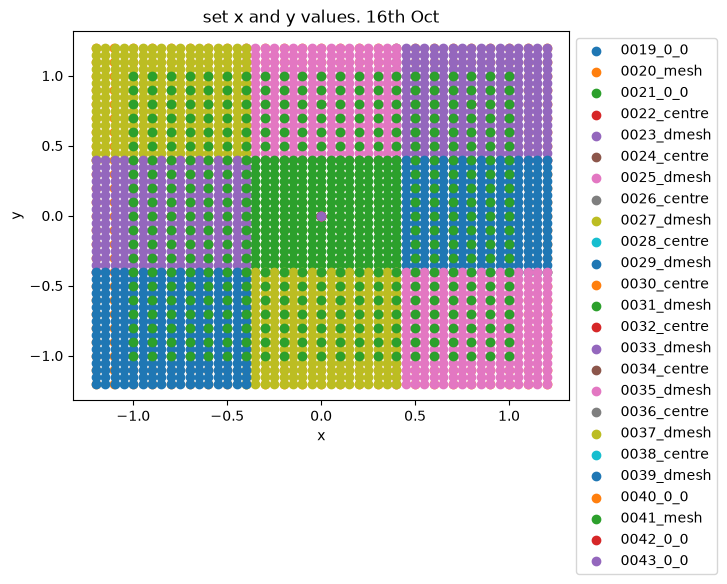

In [74]:
cmap=plt.get_cmap('Paired')
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["x"], all_data[scan]["y"], label=scan) # , color=cmap(i))
plt.ylabel("y")
plt.xlabel("x")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("set x and y values. 16th Oct")

Text(0.5, 1.0, 'measured cx and cy values 16th Oct')

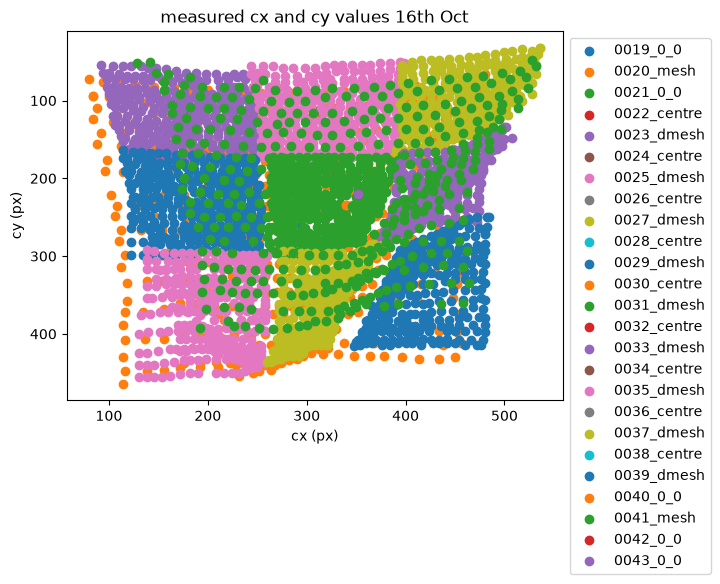

In [75]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, color=cmap(i))
plt.ylabel("cy (px)")
plt.xlabel("cx (px)")
plt.gca().invert_yaxis()
# plt.scatter(382, -270, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("measured cx and cy values 16th Oct")

Text(0.5, 1.0, 'converted cx and cy values 16th Oct')

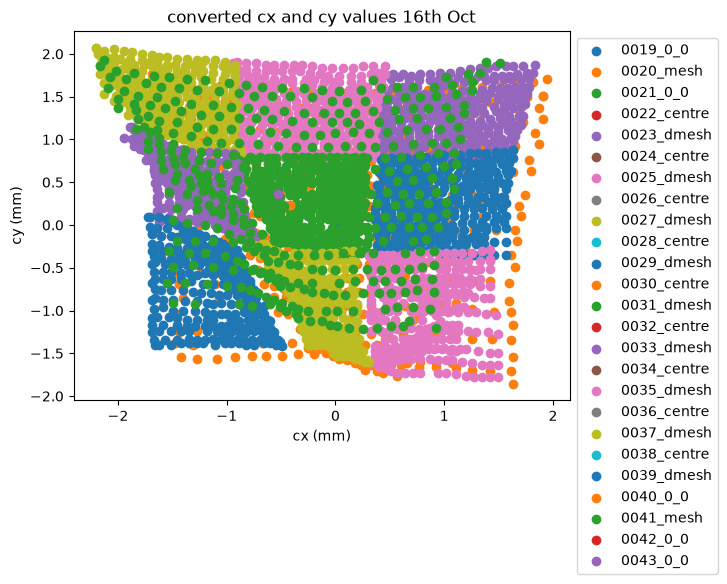

In [76]:
for i, scan in enumerate(scans): 
    plt.scatter(all_data[scan]["cx_mm"], all_data[scan]["cy_mm"], label=scan) #, color=cmap(i))
plt.ylabel("cy (mm)")
plt.xlabel("cx (mm)")
# plt.gca().invert_yaxis()
# plt.scatter(382*x_conversion, -270*y_conversion, label="initial (0,0)")
plt.legend(bbox_to_anchor=(1, 1))
plt.title("converted cx and cy values 16th Oct")

In [54]:
#check didn't track the wrong circle at one point by looking at the radius 
for scan in scans: 
    print(scan, "max: ", max(all_data[scan]["radius"].dropna()), "min: ", min(all_data[scan]["radius"].dropna()))
#all 5 or 6 - good 

0019_0_0 max:  6 min:  6
0020_mesh max:  6.0 min:  6.0
0021_0_0 max:  6 min:  6
0022_centre max:  6 min:  6
0023_dmesh max:  6.0 min:  6.0
0024_centre max:  6 min:  6
0025_dmesh max:  6.0 min:  6.0
0026_centre max:  6 min:  6
0027_dmesh max:  6.0 min:  6.0
0028_centre max:  6 min:  6
0029_dmesh max:  6 min:  6
0030_centre max:  6 min:  6
0031_dmesh max:  6.0 min:  6.0
0032_centre max:  6 min:  6
0033_dmesh max:  6.0 min:  6.0
0034_centre max:  6 min:  6
0035_dmesh max:  6.0 min:  6.0
0036_centre max:  6 min:  6
0037_dmesh max:  6.0 min:  6.0
0038_centre max:  6 min:  6
0039_dmesh max:  6.0 min:  6.0
0040_0_0 max:  6 min:  6
0041_mesh max:  6.0 min:  5.0
0042_0_0 max:  6.0 min:  6.0
0043_0_0 max:  6.0 min:  6.0


Text(0, 0, 'Colour = y')

<Figure size 640x480 with 0 Axes>

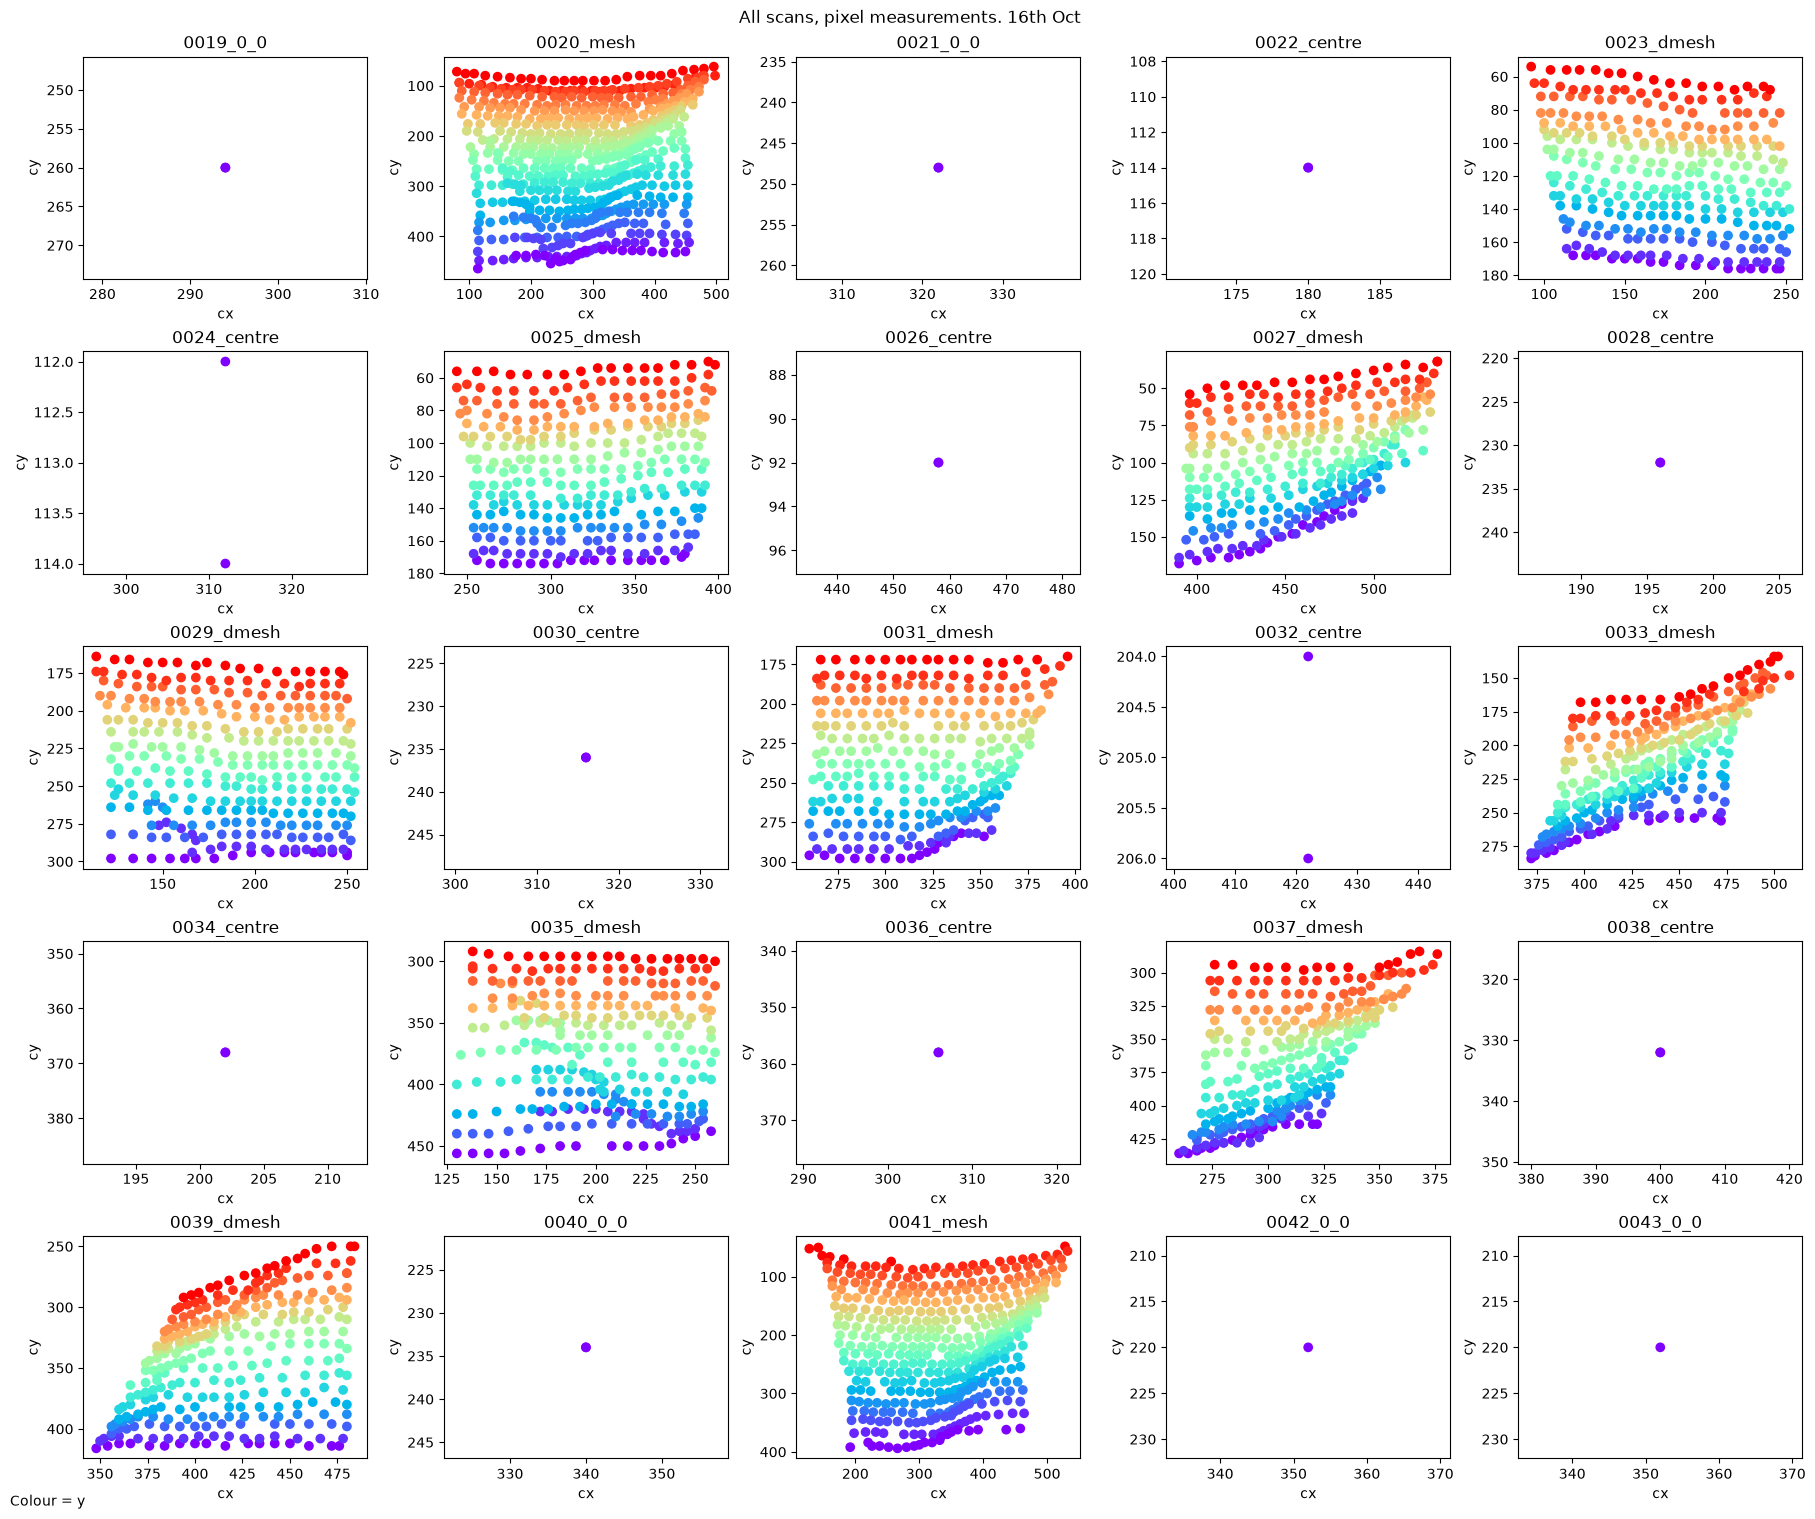

In [80]:
fig = plt.figure()
fig, ax = plt.subplots(5, 5, figsize=(18,15), constrained_layout=True)    

key = 0

for i in range(5):
    for j in range(5):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans[key]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], label=scan, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1

fig.suptitle("All scans, pixel measurements. 16th Oct")
fig.text(0,0,"Colour = y")

In [56]:
print(scans)

['0019_0_0', '0020_mesh', '0021_0_0', '0022_centre', '0023_dmesh', '0024_centre', '0025_dmesh', '0026_centre', '0027_dmesh', '0028_centre', '0029_dmesh', '0030_centre', '0031_dmesh', '0032_centre', '0033_dmesh', '0034_centre', '0035_dmesh', '0036_centre', '0037_dmesh', '0038_centre', '0039_dmesh', '0040_0_0', '0041_mesh', '0042_0_0', '0043_0_0']


Text(0, 0, 'Colour = y \n scans 28, 29 and 34 tracked the wrong circle')

<Figure size 640x480 with 0 Axes>

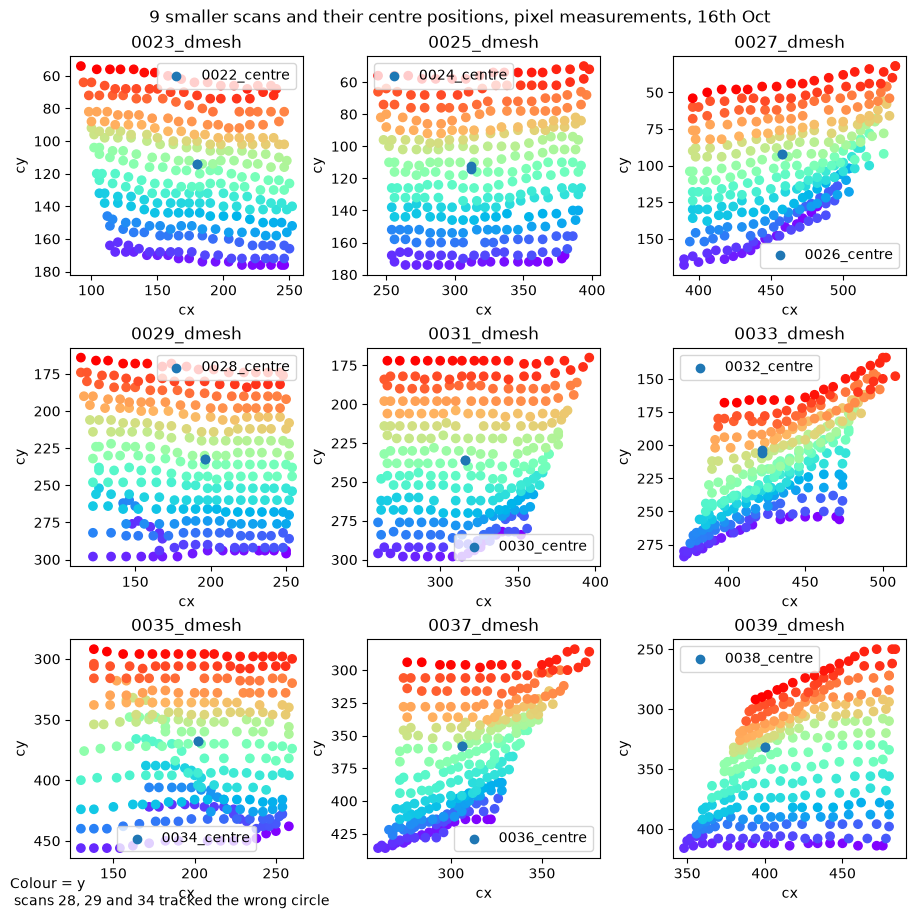

In [81]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["point"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements, 16th Oct")
fig.text(0,0,"Colour = y \n scans 28, 29 and 34 tracked the wrong circle")

(294.0, 294.0)
(322.0, 322.0)
(340.0, 340.0)
(nan, nan)
[np.int64(294), np.int64(322), np.int64(340), np.float64(352.0)]
[np.int64(260), np.int64(248), np.int64(234), np.float64(220.0)]
           2
-0.009027 x + 5.148 x - 473.2


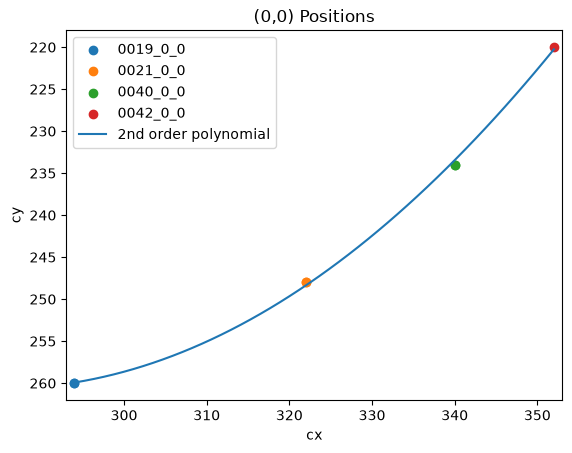

In [58]:
import math
fig, ax = plt.subplots()    

scans_i = [0,2,21,23]#,24]
scans_to_plot = [scans[i] for i in scans_i]
cx_0_0 = []
cy_0_0 = []

for scan in scans_to_plot:
    ax.scatter(all_data[scan]["cx"], all_data[scan]["cy"], label=scan) #, c=all_data[scan], cmap="rainbow")
    print((float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    ax.annotate(scan, (float(all_data[scan]["cx"][0]), float((all_data[scan]["cx"][0]))))
    if math.isnan(all_data[scan]["cx"][0]):
        cx_0_0.append(all_data[scan]["cx"][1])
    else: cx_0_0.append(all_data[scan]["cx"][0])
    if math.isnan(all_data[scan]["cy"][0]):
        cy_0_0.append(all_data[scan]["cy"][1])
    else: cy_0_0.append(all_data[scan]["cy"][0])

ax.yaxis.set_inverted(True)
ax.legend()
ax.set_ylabel("cy")
ax.set_xlabel("cx")
ax.set_title("(0,0) Positions")

print(cx_0_0)
print(cy_0_0)
z = np.polyfit(cx_0_0, cy_0_0, 2)
f = np.poly1d(z)
print(f)
# calculate new x's and y's
x_new = np.linspace(cx_0_0[0], cx_0_0[-1], 50)
y_new = f(x_new)
plt.plot(x_new, y_new, label="2nd order polynomial")
plt.xlim([cx_0_0[0]-1, cx_0_0[-1] + 1 ])
plt.legend()


Text(0, -0.02, 'Colour = y\nScans 28, 29 and 34 tracked the wrong circle')

<Figure size 640x480 with 0 Axes>

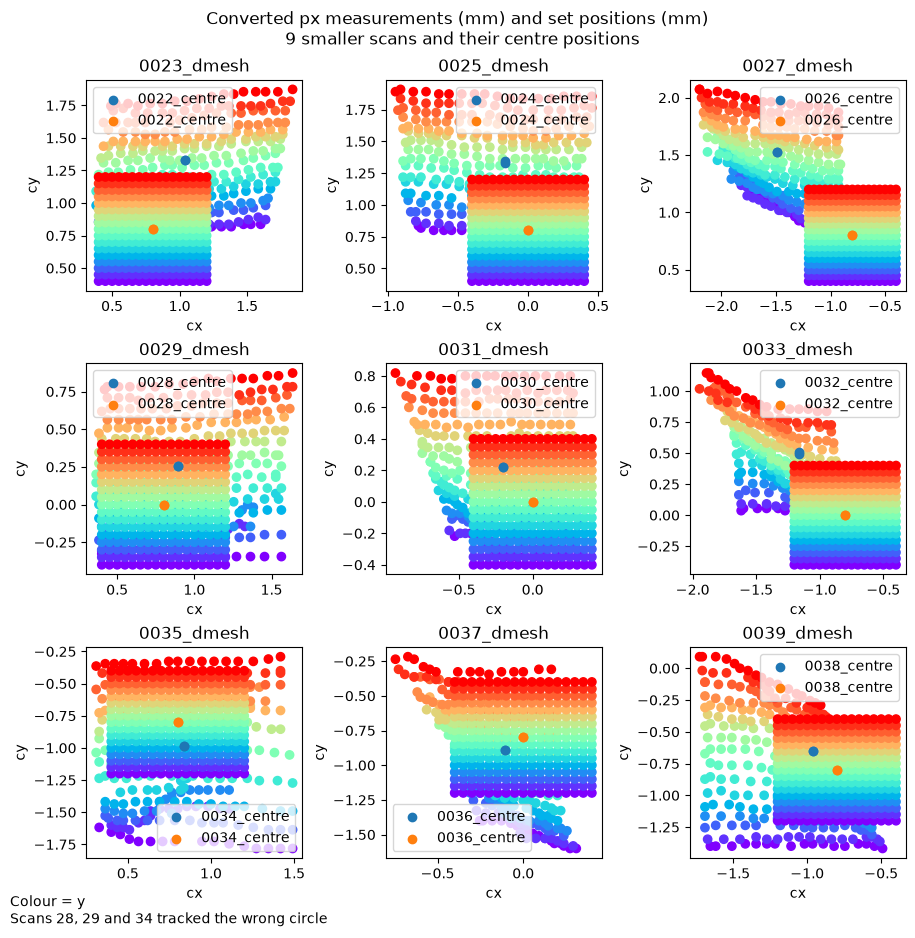

In [59]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]
        

        subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        dfCentre = scans[scans_i[key]-1]
        subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        subplot.legend()

        key += 1
fig.suptitle("Converted px measurements (mm) and set positions (mm) \n 9 smaller scans and their centre positions")
fig.text(0,-0.02,"Colour = y\nScans 28, 29 and 34 tracked the wrong circle")

0023_dmesh 0     -0.363636
1     -0.363636
2     -0.363636
3     -0.363636
4     -0.363636
         ...   
284   -0.654545
285   -0.654545
286   -0.654545
287   -0.654545
288   -0.672727
Length: 289, dtype: float64
0025_dmesh 0     -0.436364
1     -0.418182
2     -0.400000
3     -0.400000
4     -0.400000
         ...   
284   -0.636364
285   -0.636364
286   -0.654545
287   -0.654545
288   -0.654545
Length: 289, dtype: float64
0027_dmesh 0           NaN
1     -0.836364
2     -0.800000
3     -0.763636
4     -0.727273
         ...   
284   -0.727273
285   -0.727273
286   -0.727273
287   -0.709091
288   -0.672727
Length: 289, dtype: float64
0029_dmesh 0     -0.090909
1     -0.072727
2     -0.090909
3     -0.090909
4     -0.090909
         ...   
284   -0.436364
285   -0.436364
286   -0.454545
287   -0.454545
288   -0.472727
Length: 289, dtype: float64
0031_dmesh 0     -0.181818
1           NaN
2     -0.200000
3     -0.181818
4     -0.163636
         ...   
284   -0.400000
285   -0.400000
2

Text(0, -0.02, "Colour = difference between measured point and set point\n not sure what's going on with 27")

<Figure size 640x480 with 0 Axes>

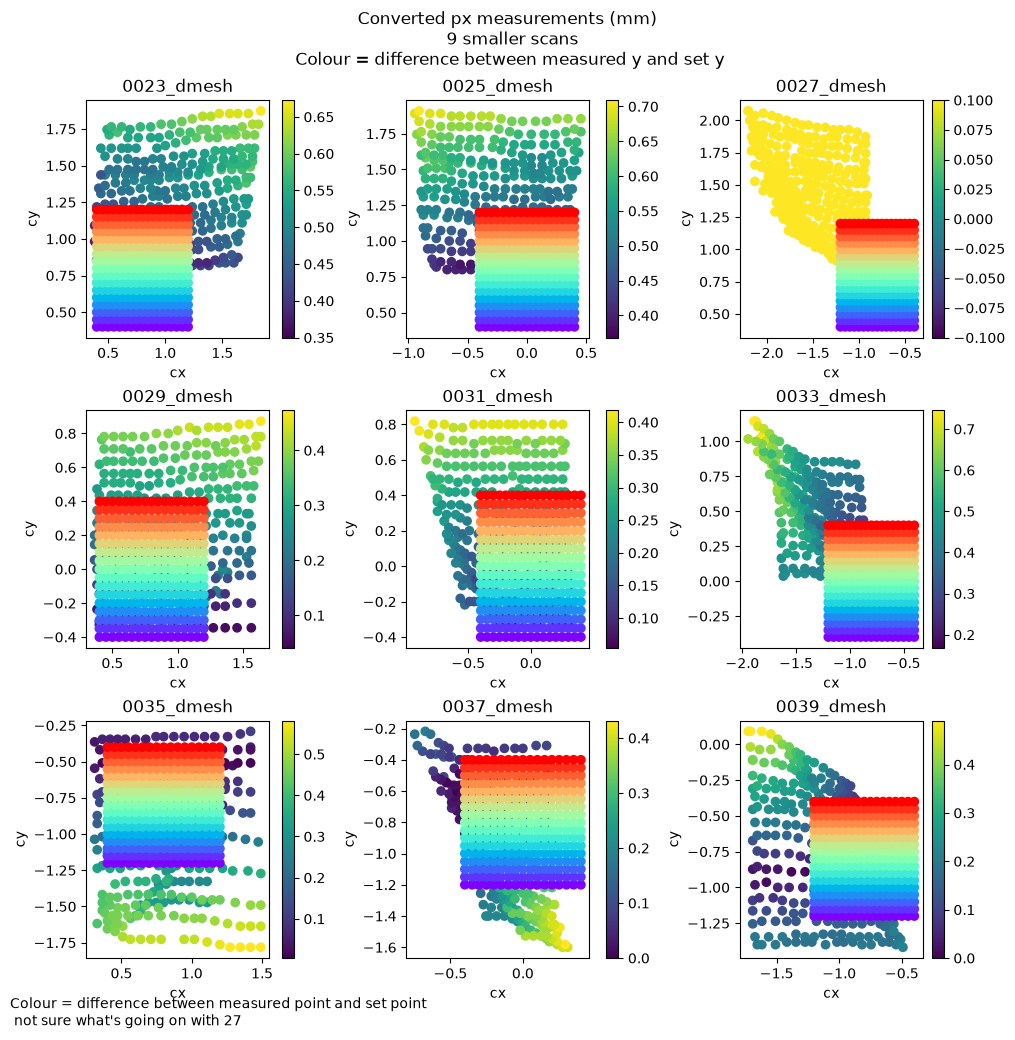

In [73]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(10,10),  constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["y"] - all_data[dfAtKey]["cy_mm"]
        print(dfAtKey, difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference), vmin=min(abs(difference)), vmax=max(abs(difference))) #cmap="rainbow") #label=scans_to_plot[key], 
        subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 
        

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        # subplot.legend()
        fig.colorbar(im, ax=subplot)  
        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
# sm =  ScalarMappable(norm=norm, cmap=cmap)
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=axes[:,1])
# cbar.ax.set_title("scale")
fig.suptitle("Converted px measurements (mm) \n 9 smaller scans\nColour = difference between measured y and set y")
fig.text(0,-0.02,"Colour = difference between measured point and set point\n not sure what's going on with 27") #\nScans 28, 29 and 34 tracked the wrong circle

Text(0, -0.02, 'Colour = difference between measured point and set point')

<Figure size 640x480 with 0 Axes>

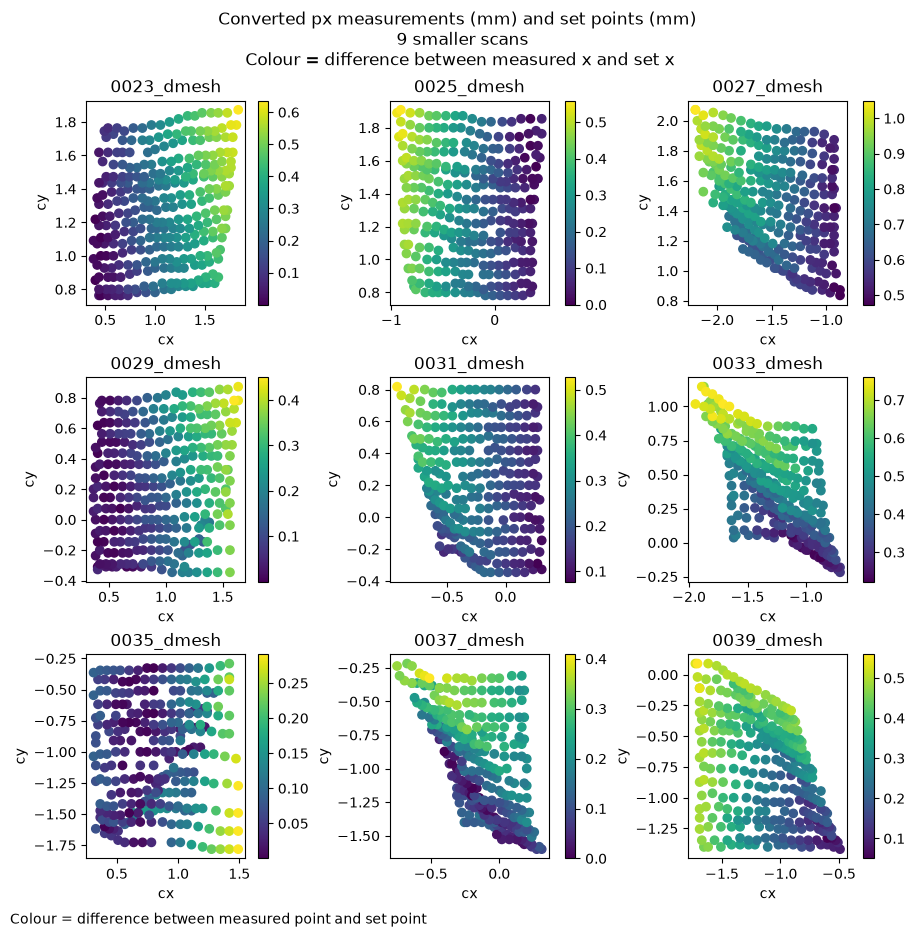

In [72]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]

        dfAtKey = scans_to_plot[key]

        difference = all_data[dfAtKey]["x"] - all_data[dfAtKey]["cx_mm"]
        # print(difference)

        im = subplot.scatter(all_data[dfAtKey]["cx_mm"], all_data[dfAtKey]["cy_mm"], c=abs(difference)) #cmap="rainbow") #label=scans_to_plot[key], 
        #subplot.scatter(all_data[dfAtKey]["x"], all_data[dfAtKey]["y"], c=all_data[dfAtKey]["y"], cmap="rainbow") #label=scans_to_plot[key], 

        #plot centre points
        # dfCentre = scans[scans_i[key]-1]
        # subplot.scatter(all_data[dfCentre]["cx_mm"], all_data[dfCentre]["cy_mm"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        # # subplot.scatter(all_data[dfCentre]["x"], all_data[dfCentre]["y"], label=scans[scans_i[key]-1])

        # subplot.yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        subplot.set_xlabel("cx")
        subplot.set_ylabel("cy")
        fig.colorbar(im, ax=subplot)  
        # subplot.legend()

        key += 1
# plt.colorbar(im, ax=ax.ravel().tolist())  
fig.suptitle("Converted px measurements (mm) and set points (mm) \n 9 smaller scans\nColour = difference between measured x and set x")
fig.text(0,-0.02,"Colour = difference between measured point and set point") #\nScans 28, 29 and 34 tracked the wrong circle")

Text(0, 0, 'Colour = point')

<Figure size 640x480 with 0 Axes>

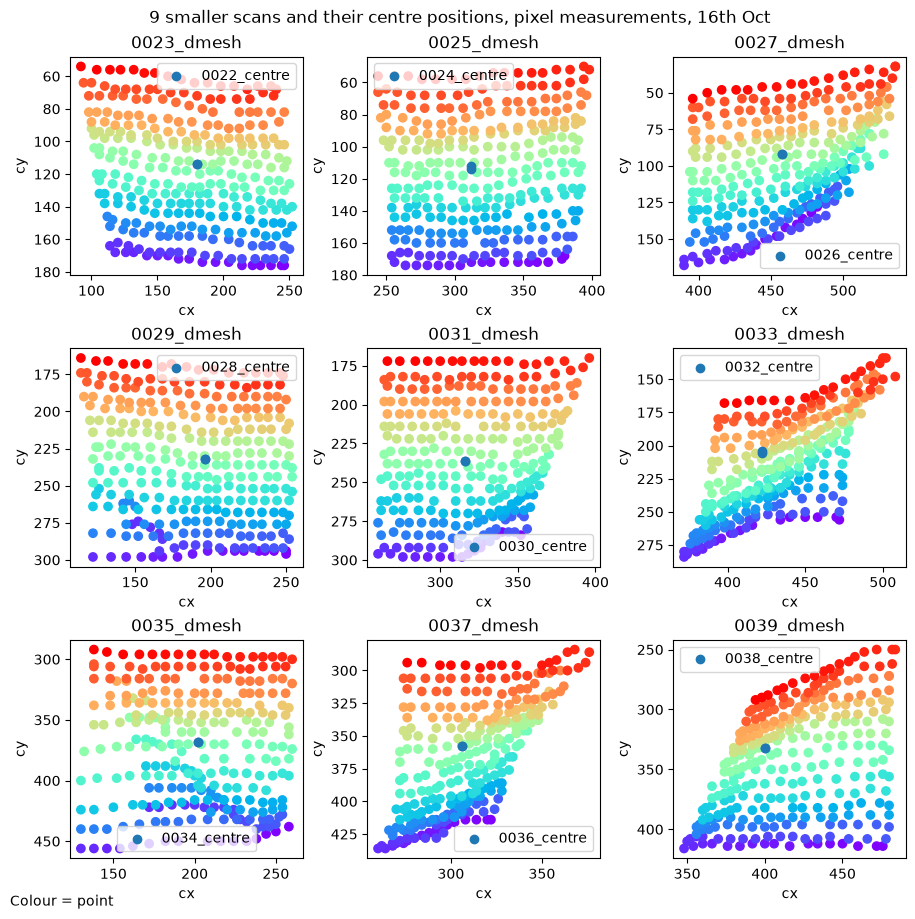

In [96]:
fig = plt.figure()
fig, ax = plt.subplots(3, 3, figsize=(9,9), constrained_layout=True)    

key = 0
scans_i = [4,6,8,10,12,14,16,18,20]
scans_to_plot = [scans[i] for i in scans_i]
for i in range(3):
    for j in range(3):
        subplot = ax[i,j]
        # print(key)
        dfAtKey = scans_to_plot[key]
        dfCentre = scans[scans_i[key]-1]
        # print(dfAtKey)
        ax[i,j].scatter(all_data[dfAtKey]["cx"], all_data[dfAtKey]["cy"], c=all_data[dfAtKey]["point"], cmap="rainbow") #label=scans_to_plot[key], 
        ax[i,j].scatter(all_data[dfCentre]["cx"], all_data[dfCentre]["cy"], label=scans[scans_i[key]-1]) #, c=all_data[dfAtKey]["y"], cmap="rainbow")
        ax[i,j].yaxis.set_inverted(True)
        subplot.set_title(scans_to_plot[key])
        ax[i,j].set_xlabel("cx")
        ax[i,j].set_ylabel("cy")
        ax[i,j].legend()
        # for ind in dfAtKey.index:
        #     subplot.scatter(dfAtKey.loc[ind,0] , dfAtKey.loc[ind,1] , width = 0.5,  label=scan)

        key += 1
fig.suptitle("9 smaller scans and their centre positions, pixel measurements, 16th Oct")
fig.text(0,0,"Colour = point")# \n scans 28, 29 and 34 tracked the wrong circle")